# Answers Problem 2

**Table of contents**<a id='toc0_'></a>    
- 1. [Aggregate inflation in Denmark](#toc1_)    
  - 1.1. [Data](#toc1_1_)    
  - 1.2. [Month-to-month inflation rate](#toc1_2_)    
  - 1.3. [12-month inflation rate](#toc1_3_)    
  - 1.4. [Instantaneous inflation](#toc1_4_)    
    - 1.4.1. [Weights](#toc1_4_1_)    
    - 1.4.2. [Results](#toc1_4_2_)    
  - 1.5. [Core inflation](#toc1_5_)    
- 2. [International comparison](#toc2_)    
  - 2.1. [Denmark: CPI vs HICP](#toc2_1_)    
  - 2.2. [Cross-country](#toc2_2_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
plt.rcParams.update({'axes.grid':True,'grid.color':'black','grid.alpha':'0.25','grid.linestyle':'--'})
plt.rcParams.update({'font.size': 14})

from dstapi import DstApi
from fredapi import Fred

## 1. <a id='toc1_'></a>[Aggregate inflation in Denmark](#toc0_)

### 1.1. <a id='toc1_1_'></a>[Data](#toc0_)

In [2]:
PRIS113 = DstApi('PRIS113')

In [3]:
PRIS113.tablesummary(language='en')

Table PRIS113: Consumer price index by type and time
Last update: 2026-01-12T08:00:00


,variable name,# values,First value,First value label,Last value,Last value label,Time variable
0,TYPE,1,INDEKS,Consumer price index,INDEKS,Consumer price index,False
1,Tid,552,1980M01,1980M01,2025M12,2025M12,True


In [ ]:
# a. download data
params = PRIS113._define_base_params(language='en')
df_CPI = PRIS113.get_data(params)

# b. clean data
df_CPI = df_CPI.drop(columns=['TYPE'])
df_CPI['TID'] = pd.to_datetime(df_CPI['TID'],format='%YM%m')
df_CPI = df_CPI.rename(columns={'TID':'date','INDHOLD':'CPI'})
df_CPI['CPI'] = df_CPI['CPI'].astype(float)
df_CPI = df_CPI.set_index('date').sort_index()

# c. index to 2020=100
df_CPI.CPI = df_CPI.CPI/df_CPI[df_CPI.index.year==2020].CPI.mean()*100
df_CPI.tail()

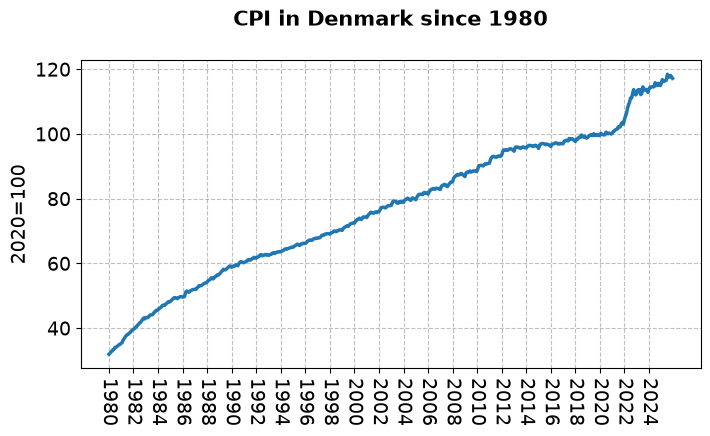

In [5]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

ax.plot(df_CPI.index,df_CPI.CPI,lw=2.5)

ax.set_xticks(df_CPI.index[::24])
ax.set_xticklabels(df_CPI.index[::24].year,rotation=270);

ax.set_ylabel('2020=100')
ax.set_title('CPI in Denmark since 1980',
             pad=25.0,fontdict={'fontsize':15,'fontweight':'bold'});

### 1.2. <a id='toc1_2_'></a>[Month-to-month inflation rate](#toc0_)

In [6]:
df_CPI['inflation'] = df_CPI['CPI'].pct_change(periods=1,fill_method=None)*100

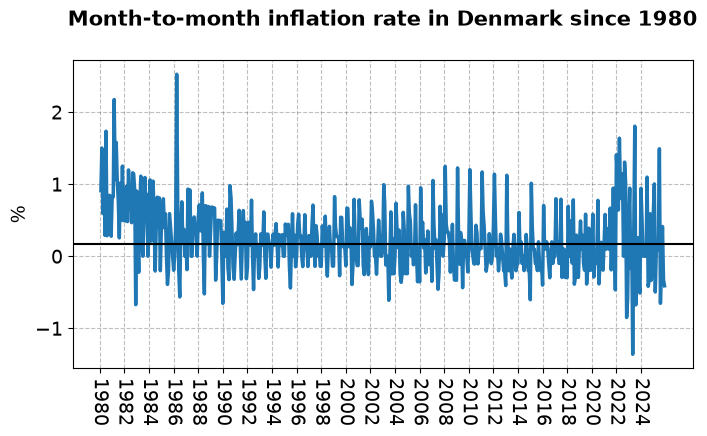

In [7]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

ax.plot(df_CPI.index,df_CPI['inflation'],lw=2.5)

ax.axhline(((1+0.02)**(1/12)-1)*100,color='black')

ax.set_xticks(df_CPI.index[::24])
ax.set_xticklabels(df_CPI.index[::24].year,rotation=270);

ax.set_ylabel('%')
ax.set_title('Month-to-month inflation rate in Denmark since 1980',
             pad=25.0,fontdict={'fontsize':15,'fontweight':'bold'});

### 1.3. <a id='toc1_3_'></a>[12-month inflation rate](#toc0_)

In [ ]:
df_CPI['inflation_12'] = df_CPI['CPI'].pct_change(periods=12,fill_method=None)*100

In [ ]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

ax.plot(df_CPI.index,df_CPI['inflation_12'],lw=2.5)

ax.axhline(2.0,color='black')

ax.set_xticks(df_CPI.index[::24])
ax.set_xticklabels(df_CPI.index[::24].year,rotation=270);

ax.set_ylabel('%')
ax.set_title('12-month inflation rate in Denmark since 1980',
             pad=25.0,fontdict={'fontsize':15,'fontweight':'bold'});

### 1.4. <a id='toc1_4_'></a>[Instantaneous inflation](#toc0_)

#### 1.4.1. <a id='toc1_4_1_'></a>[Weights](#toc0_)

In [10]:
a_vec = np.array([0.0,1.0,2.0,3.0])
Na = a_vec.size
weights = np.zeros((Na,12))
for i_a in range(Na):
    weights[i_a] = (12-np.flip(np.arange(12)))**a_vec[i_a]
    weights[i_a] = weights[i_a]/np.sum(weights[i_a])*12

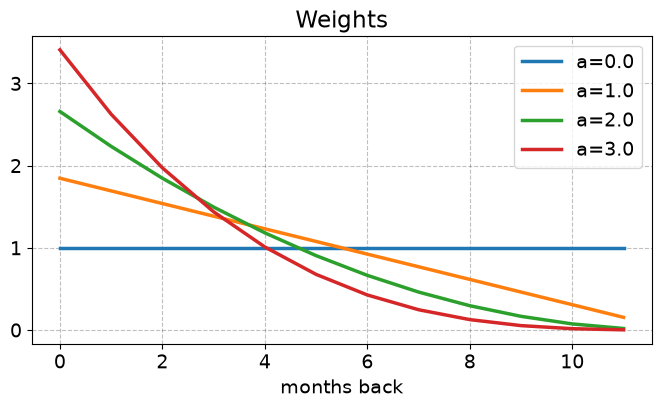

In [11]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

for i_a in range(Na):
    ax.plot(np.flip(np.arange(12)),weights[i_a],label=f'a={a_vec[i_a]:.1f}',lw=2.5)

ax.legend()
ax.set_xlabel('months back')
ax.set_title('Weights');

#### 1.4.2. <a id='toc1_4_2_'></a>[Results](#toc0_)

In [12]:
for i_a in range(Na):
    df_CPI[f'inflation_{i_a}'] = df_CPI.inflation.rolling(12).apply(lambda x: (np.prod((1+x/100)**(weights[i_a]))-1)*100)

In [ ]:
I = df_CPI.index >= pd.to_datetime('2019',format='%Y')

fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

for i_a in range(Na):
    ax.plot(df_CPI[I].index,df_CPI[I][f'inflation_{i_a}'],lw=2.5,label=f'a={a_vec[i_a]:.1f}')

ax.axhline(2,color='black')

ax.set_xticks(df_CPI[I].index[::12])
ax.set_xticklabels(df_CPI[I].index[::12].year,rotation=270);

ax.legend()
ax.set_ylabel('%')
ax.set_title('Instantaneous inflation in Denmark since 2019',
             pad=25.0,fontdict={'fontsize':15,'fontweight':'bold'});

### 1.5. <a id='toc1_5_'></a>[Core inflation](#toc0_)

In [14]:
PRIS111 = DstApi('PRIS111')

In [15]:
PRIS111.tablesummary(language='en')

Table PRIS111: Consumer price index by commodity group, unit and time
Last update: 2026-01-12T08:00:00


,variable name,# values,First value,First value label,Last value,Last value label,Time variable
0,VAREGR,385,000000,"00 Consumer price index, total",151000,15.1 Overall Consumer Price Index excl. energy,False
1,ENHED,3,100,Index,300,Percentage change compared to same month the y...,False
2,Tid,300,2001M01,2001M01,2025M12,2025M12,True


In [ ]:
dict_VAREGR = {row['id']: row['text'] for i,row in PRIS111.variable_levels('VAREGR',language='en').iterrows()}
dict_ENHED = {row['id']: row['text'] for i,row in PRIS111.variable_levels('ENHED',language='en').iterrows()}

In [ ]:
# a. download data
params = PRIS111._define_base_params(language='en')
VAREGR = {'code': 'VAREGR', 'values': ['000000', '141000','151000']}
ENHED = {'code': 'ENHED', 'values': ['100']}
TID = {'code': 'Tid', 'values': ['*']}
params['variables'] = [VAREGR, ENHED, TID]
df_CPI_core = PRIS111.get_data(params)

# b. clean data
df_CPI_core['VAREGR'] = df_CPI_core.VAREGR.replace(
    {dict_VAREGR['000000']: 'Total',
     dict_VAREGR['141000']: 'Core',
     dict_VAREGR['151000']: 'ExclEnergy'
    })
df_CPI_core = df_CPI_core.rename(columns={'TID':'date','INDHOLD': 'value',})
df_CPI_core = df_CPI_core.drop(columns=['ENHED'])
df_CPI_core['date'] = pd.to_datetime(df_CPI_core['date'], format='%YM%m')
df_CPI_core['value'] = df_CPI_core.value.astype(float)

# c. pivot
df_CPI_core = df_CPI_core.pivot_table(index='date',columns='VAREGR',values='value').rename_axis(None,axis=1)

# d. inflation rates
df_CPI_core['inflation_12_total'] = df_CPI_core['Total'].pct_change(periods=12,fill_method=None)*100
df_CPI_core['inflation_12_excl_energy'] = df_CPI_core['ExclEnergy'].pct_change(periods=12,fill_method=None)*100
df_CPI_core['inflation_12_core'] = df_CPI_core['Core'].pct_change(periods=12,fill_method=None)*100
df_CPI_core.tail()

In [ ]:
I = df_CPI_core.index >= pd.to_datetime('2019',format='%Y')

fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

ax.plot(df_CPI_core[I]['inflation_12_total'],lw=2.5,label='Total')
ax.plot(df_CPI_core[I]['inflation_12_excl_energy'],lw=2.5,label='Excl. energy')
ax.plot(df_CPI_core[I]['inflation_12_core'],lw=2.5,label='Core')

ax.axhline(2,color='black')

ax.set_xticks(df_CPI_core[I].index[::12])
ax.set_xticklabels(df_CPI_core[I].index[::12].year,rotation=270);

ax.set_ylabel('%')
ax.legend()
ax.set_title('Total vs core inflation in Denmark since 2019',
             pad=25.0,fontdict={'fontsize':15,'fontweight':'bold'});

## 2. <a id='toc2_'></a>[International comparison](#toc0_)

In [19]:
with open('c:/Users/gmf123/Dropbox/fredapi.txt', 'r') as f: fred_api_key = f.read()
fred = Fred(api_key=fred_api_key)

### 2.1. <a id='toc2_1_'></a>[Denmark: CPI vs HICP](#toc0_)

In [20]:
df_CPI_HICP = df_CPI.loc[:,['CPI']]
df_CPI_HICP['HICP'] = fred.get_series('CP0000DKM086NEST').rename('HICP')
df_CPI_HICP['HICP'] = df_CPI_HICP.HICP/df_CPI_HICP[df_CPI_HICP.index.year==2020].HICP.mean()*100

In [21]:
df_CPI_HICP.tail()

,CPI,HICP
date,,
2025-08-01,117.660329,118.583740
2025-09-01,117.563648,118.430440
2025-10-01,118.047051,119.079018
2025-11-01,117.660329,118.477609
2025-12-01,117.176926,117.958746


In [ ]:
I = df_CPI_HICP.index >= pd.to_datetime('1997',format='%Y')

fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

ax.plot(df_CPI_HICP[I].index, df_CPI_HICP[I].CPI,lw=2.5,label='CPI')
ax.plot(df_CPI_HICP[I].index, df_CPI_HICP[I].HICP,lw=2.5,label='HICP')

ax.set_xticks(df_CPI_HICP[I].index[::24])
ax.set_xticklabels(df_CPI_HICP[I].index[::24].year,rotation=270);

ax.legend()
ax.set_ylabel('2020=100')
ax.set_title('CPI and HICP in Denmark since 1997',
             pad=25.0,fontdict={'fontsize':15,'fontweight':'bold'});

### 2.2. <a id='toc2_2_'></a>[Cross-country](#toc0_)

In [23]:
countries = {
    'Denmark': 'Denmark',
    'Austria': 'Austria',
    'EuroArea': 'Euro Area',
    'UnitedStates': 'United States',
}

series = {
    'CP0000DKM086NEST': 'Denmark',
    'CP0000ATM086NEST': 'Austria',
    'CP0000EZ19M086NEST': 'EuroArea',
    'CP0000USM086NEST': 'UnitedStates',    
}

Check data:

In [ ]:
for k,v in series.items():
    label = fred.search(k)[['title']].values[0][0]
    print(f'{v}: {label}')

Download data:

In [25]:
data = {}
for code,name in series.items():
    data[name] = fred.get_series(code)
df_int = pd.DataFrame(data)

In [26]:
df_int = df_int/df_int[df_int.index.year==2020].mean()*100
df_int.tail()

,Denmark,Austria,EuroArea,UnitedStates
2026-02-01,118.253555,130.015486,123.345140,NaN
2026-03-01,118.218178,131.514925,124.912983,NaN
2026-04-01,118.536571,132.194158,126.186855,NaN
2026-05-01,119.267696,132.309500,126.284845,NaN
2026-06-01,119.586089,131.976291,126.162357,NaN


In [ ]:
I = df_int.index >= pd.to_datetime('2019',format='%Y')

fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

for code, name in countries.items():
    ax.plot(df_int[I].index, df_int[I][code], lw=2.5,label=name)

ax.set_xticks(df_int[I].index[::24])
ax.set_xticklabels(df_int[I].index[::24].year,rotation=270);

ax.legend()
ax.set_ylabel('2020=100')
ax.set_title('HICP across countries since 2019',
             pad=25.0,fontdict={'fontsize': 15, 'fontweight': 'bold'});

In [28]:
df_int_pct_change = df_int.pct_change(periods=12,fill_method=None)*100

In [ ]:
I = df_int_pct_change.index >= pd.to_datetime('2019',format='%Y')

fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

for code, name in countries.items():
    ax.plot(df_int_pct_change[I].index, df_int_pct_change[I][code], lw=2.5,label=name)

ax.axhline(2,color='black')

ax.set_xticks(df_int_pct_change[I].index[::24])
ax.set_xticklabels(df_int_pct_change[I].index[::24].year,rotation=270);

ax.legend()
ax.set_ylabel('%')
ax.set_title('12-month HICP inflation across countries since 2019',
             pad=25.0,fontdict={'fontsize': 15, 'fontweight': 'bold'});